# Лабораторная работа № 2. Классификация данных

**Датасет:** Beer Consumption — São Paulo.  
**Задача:** по четырём погодным признакам определить, превысит ли суточное потребление пива порог 25,0 в числовой шкале исходного CSV.

## 1. Цель работы

Изучить методы классификации Scikit-Learn, сравнить их по пяти метрикам, оценить влияние гиперпараметров и обучить полносвязную нейросеть в TensorFlow с мониторингом в TensorBoard.

Таблицы, прогнозы и графики включены в блокнот. Для просмотра достаточно открыть файл в JupyterLab. Для выполнения ячеек нужны NumPy, pandas, Matplotlib и Scikit-Learn. TensorFlow и TensorBoard нужны для повторного обучения и открытия панели мониторинга соответственно. Настройки по умолчанию используют сохранённый запуск TensorFlow и повторяют расчёт классических моделей.

In [1]:
from ast import literal_eval
from base64 import b64decode
from datetime import datetime
from io import BytesIO
from pathlib import Path
from zipfile import ZipFile
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from IPython.display import display
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score, confusion_matrix, f1_score, precision_score,
    recall_score, roc_auc_score, roc_curve,
)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_score, train_test_split
from sklearn.naive_bayes import BernoulliNB, ComplementNB, GaussianNB, MultinomialNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import Binarizer, KBinsDiscretizer, StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

SEED = 42
THRESHOLD = 25.0
RAW_CSV = None  # При наличии исходного CSV: Path("Consumo_cerveja.csv")
RETRAIN_TF = False  # True для повторного обучения TensorFlow
OPEN_TENSORBOARD = False  # True для открытия панели в JupyterLab
LOG_DIR = Path("logs/lab2")

FEATURES = [
    "Temperatura Media (C)", "Temperatura Minima (C)",
    "Temperatura Maxima (C)", "Precipitacao (mm)",
]
TARGET = "Consumo de cerveja (litros)"
LABEL = "high_consumption"
METRICS = ["Accuracy", "Precision", "Recall", "F1", "ROC_AUC"]

### Данные для воспроизведения

Следующая свёрнутая ячейка содержит очищенный CSV и результаты исходного запуска: разбиение, прогнозы, таблицы подбора параметров и историю обучения. 

In [2]:
packed_results = (
    "..."
)

with ZipFile(BytesIO(b64decode(packed_results))) as bundle:
    saved_data = pd.read_csv(bundle.open("clean_data.csv"), parse_dates=["Data"])
    saved_split = pd.read_csv(bundle.open("split.csv")).set_index("row_id")["part"]
    saved_predictions = pd.read_csv(bundle.open("test_predictions.csv")).set_index("row_id")
    saved_metrics = pd.read_csv(bundle.open("metrics.csv")).set_index("Model")
    saved_tuning = pd.read_csv(bundle.open("classical_tuning.csv")).set_index("Model")
    saved_nn = pd.read_csv(bundle.open("nn_experiments.csv")).set_index("id")
    saved_histories = json.loads(bundle.read("nn_histories.json"))
    run_metadata = json.loads(bundle.read("metadata.json"))
    saved_grids = {
        name: pd.read_csv(bundle.open(name.replace(" ", "_") + "_grid.csv"))
        for name in saved_tuning.index
    }
del packed_results

## 2. Датасет и подготовка данных

[Beer Consumption — São Paulo](https://www.kaggle.com/datasets/dongeorge/beer-consumption-sao-paulo) содержит ежедневные наблюдения за 2015 год. В исходной загрузке было 941 строка с учётом пустых записей. После очистки осталось 365 дней с 1 января по 31 декабря. При чтении исходного CSV числовые поля с десятичной запятой переводятся в числовой формат, даты разбираются, строки без обязательных значений удаляются.

| Признак | Описание |
|---|---|
| `Temperatura Media (C)` | Средняя температура, °C |
| `Temperatura Minima (C)` | Минимальная температура, °C |
| `Temperatura Maxima (C)` | Максимальная температура, °C |
| `Precipitacao (mm)` | Осадки, мм |

Метка равна 1, если `Consumo de cerveja (litros) > 25.0`, и 0 во всех остальных случаях. Порог задан до обучения в шкале CSV. Получено 177 дней класса 1 и 188 дней класса 0. Столбец потребления используется только для построения метки. Дата и флаг выходного исключены из признаков, чтобы сравнить модели на одном наборе из четырёх погодных показателей.

In [3]:
def prepare_original_csv(path):
    frame = pd.read_csv(path)
    frame["Data"] = pd.to_datetime(frame["Data"], errors="coerce")
    for col in [*FEATURES, "Final de Semana", TARGET]:
        numbers = frame[col].astype("string").str.replace(",", ".", regex=False)
        frame[col] = pd.to_numeric(numbers, errors="coerce").astype("float64")
    frame = frame.dropna(subset=["Data", *FEATURES, TARGET])
    return frame.sort_values("Data").reset_index(drop=True)


data = saved_data.copy() if RAW_CSV is None else prepare_original_csv(RAW_CSV)
data[LABEL] = (data[TARGET] > THRESHOLD).astype(int)
X, y = data[FEATURES], data[LABEL]

assert data["Data"].is_unique and not X.isna().any().any()
assert len(data) == run_metadata["n"]
display(data[["Data", *FEATURES, LABEL]].head())

,Data,Temperatura Media (C),Temperatura Minima (C),Temperatura Maxima (C),Precipitacao (mm),high_consumption
0,2015-01-01,27.30,23.9,32.5,0.0,1
1,2015-01-02,27.02,24.5,33.5,0.0,1
2,2015-01-03,24.82,22.4,29.9,0.0,1
3,2015-01-04,23.98,21.5,28.6,1.2,1
4,2015-01-05,23.82,21.0,28.3,0.0,1


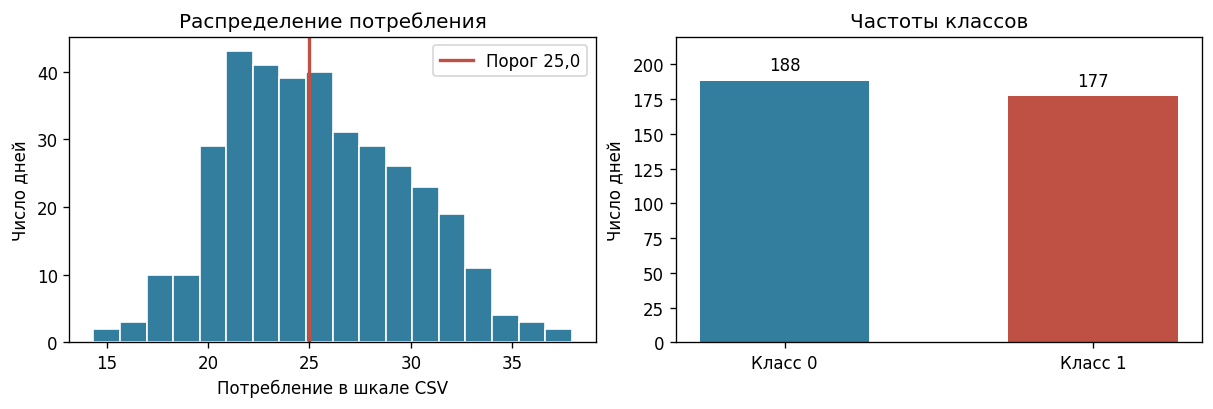

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.3), layout="constrained")
axes[0].hist(data[TARGET], bins=18, color="#337e9e", edgecolor="white")
axes[0].axvline(THRESHOLD, color="#be5143", lw=2, label="Порог 25,0")
axes[0].set(xlabel="Потребление в шкале CSV", ylabel="Число дней", title="Распределение потребления")
axes[0].legend()
counts = y.value_counts().sort_index()
bars = axes[1].bar(["Класс 0", "Класс 1"], counts, color=["#337e9e", "#be5143"], width=0.55)
axes[1].bar_label(bars, padding=4)
axes[1].set(ylim=(0, 220), ylabel="Число дней", title="Частоты классов")
plt.show()

## 3. Разбиение выборки

Данные стратифицированно разделены на обучение и тест в соотношении 80/20 с `random_state=42`. Для подбора классических моделей использована стратифицированная кросс-валидация на пяти фолдах внутри обучающей части. Для экспериментов с нейросетью из тех же 292 дней выделены 59 дней на валидацию, остальные 233 использованы для подбора архитектуры.

Масштабирование и дискретизация классических моделей входят в `Pipeline` и обучаются на тренировочной части каждого фолда. При настройке нейросети масштабирование обучается на её внутренней тренировочной части. После выбора параметров модели переобучаются на 292 днях, затем оцениваются на одном и том же тесте из 73 дней. Разбиение случайное, поэтому результаты характеризуют классификацию дней в этом наборе. Для прогноза на будущий период потребовалась бы отдельная проверка с хронологическим разбиением.

In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=SEED,
)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

assert np.array_equal(X_test.index, saved_predictions.index)
assert set(X_test.index) == set(saved_split[saved_split == "test"].index)
assert not X_train.index.intersection(X_test.index).size

split_table = pd.DataFrame({
    "Обучение": y_train.value_counts().sort_index(),
    "Тест": y_test.value_counts().sort_index(),
}).T.rename(columns={0: "Класс 0", 1: "Класс 1"})
split_table["Всего"] = split_table.sum(axis=1)
display(split_table)

high_consumption,Класс 0,Класс 1,Всего
Обучение,150,142,292
Тест,38,35,73


## 4. Методы классификации

| Метод | Принцип и преобразование признаков |
|---|---|
| DummyClassifier | Контрольный ориентир: всегда предсказывает самый частый класс. |
| GaussianNB | Применяет правило Байеса с предположением условной независимости признаков и нормальным распределением каждого признака внутри класса. Используется стандартизация. |
| MultinomialNB | Оценивает класс по неотрицательным признакам. Непрерывные значения переводятся в интервалы равной ширины и кодируются индикаторами. |
| ComplementNB | Оценивает веса признаков по наблюдениям из дополнения каждого класса. Используются те же индикаторы интервалов. |
| BernoulliNB | Моделирует вероятность наличия или отсутствия бинарного признака. Стандартизованные показатели бинаризуются по порогу. |
| Decision Tree | Строит последовательность пороговых условий, разделяющих наблюдения на группы. Использует исходные числовые значения. |
| Linear Discriminant Analysis (LDA) | Разделяет классы линейной границей, предполагая общую ковариацию признаков внутри классов. |
| Support Vector Machine (SVM) | Строит границу с максимальным зазором. Для стандартизованных признаков проверяются линейное ядро и RBF. |
| k-Nearest Neighbors (kNN) | Определяет класс голосованием ближайших наблюдений. Стандартизация приводит признаки к сопоставимому масштабу. |

In [6]:
def scaled(estimator):
    return Pipeline([("scale", StandardScaler()), ("model", estimator)])


def discretized(estimator):
    bins = KBinsDiscretizer(n_bins=3, encode="onehot", strategy="uniform")
    return Pipeline([("bins", bins), ("model", estimator)])


models = {
    "GaussianNB": scaled(GaussianNB()),
    "MultinomialNB": discretized(MultinomialNB()),
    "ComplementNB": discretized(ComplementNB()),
    "BernoulliNB": Pipeline([
        ("scale", StandardScaler()), ("binary", Binarizer()),
        ("model", BernoulliNB(binarize=None)),
    ]),
    "Decision Tree": Pipeline([("model", DecisionTreeClassifier(random_state=SEED))]),
    "LDA": Pipeline([("model", LinearDiscriminantAnalysis())]),
    "SVM": scaled(SVC()),
    "kNN": scaled(KNeighborsClassifier()),
}


def get_scores(model, features):
    if hasattr(model, "decision_function"):
        return model.decision_function(features)
    return model.predict_proba(features)[:, 1]

## 5. Настройка гиперпараметров

Сравнивались 112 комбинаций параметров. Для каждой конфигурации считался средний ROC-AUC по пяти валидационным фолдам. Выбиралась комбинация с наибольшим средним, после чего её модель обучалась на всей обучающей части. Встроенные таблицы подбора содержат значения параметров и ROC-AUC по каждому фолду.

In [7]:
classical_scores = pd.DataFrame(index=X_test.index.rename("row_id"))
replayed_tuning = []
baseline = DummyClassifier(strategy="prior").fit(X_train, y_train)
classical_scores["Dummy (baseline)_score"] = get_scores(baseline, X_test)
classical_scores["Dummy (baseline)_pred"] = baseline.predict(X_test)

for name, model in models.items():
    grid = [
        {key: [value] for key, value in literal_eval(params).items()}
        for params in saved_grids[name]["params"]
    ]
    search = GridSearchCV(model, grid, scoring="roc_auc", cv=cv)
    search.fit(X_train, y_train)
    base_auc = cross_val_score(model, X_train, y_train, scoring="roc_auc", cv=cv).mean()
    replayed_tuning.append({
        "Модель": name,
        "Базовый ROC-AUC CV": base_auc,
        "Лучший ROC-AUC CV": search.best_score_,
    })
    classical_scores[name + "_score"] = get_scores(search, X_test)
    classical_scores[name + "_pred"] = search.predict(X_test)

replayed_tuning = pd.DataFrame(replayed_tuning).set_index("Модель")
tuning_table = saved_tuning.rename(columns={
    "Base_CV_AUC": "Базовый ROC-AUC", "Best_CV_AUC": "Лучший ROC-AUC",
    "CV_std": "Ст. откл. по фолдам", "Best_params": "Лучшие параметры",
}).copy()
tuning_table["Прирост"] = tuning_table["Лучший ROC-AUC"] - tuning_table["Базовый ROC-AUC"]
tuning_table["Лучшие параметры"] = tuning_table["Лучшие параметры"].map(
    lambda row: ", ".join(f"{key.split('__')[-1]}={value}" for key, value in json.loads(row).items())
)
display(tuning_table[[
    "Базовый ROC-AUC", "Лучший ROC-AUC", "Прирост", "Ст. откл. по фолдам", "Лучшие параметры",
]].round(4))

,Базовый ROC-AUC,Лучший ROC-AUC,Прирост,Ст. откл. по фолдам,Лучшие параметры
Model,,,,,
GaussianNB,0.7601,0.7664,0.0063,0.0298,var_smoothing=1.0
MultinomialNB,0.7466,0.7609,0.0142,0.0421,"n_bins=5, alpha=0.01"
ComplementNB,0.7466,0.7616,0.0149,0.0433,"n_bins=5, alpha=0.01, norm=True"
BernoulliNB,0.7322,0.7322,0.0000,0.0468,"threshold=0, alpha=1, fit_prior=True"
Decision Tree,0.6445,0.7745,0.1301,0.0122,"criterion=gini, max_depth=2, min_samples_leaf=1"
LDA,0.7911,0.7922,0.0010,0.0210,"shrinkage=auto, solver=lsqr"
SVM,0.7708,0.7897,0.0189,0.0201,"C=0.1, kernel=linear"
kNN,0.7443,0.7723,0.0280,0.0249,"n_neighbors=21, p=1, weights=uniform"


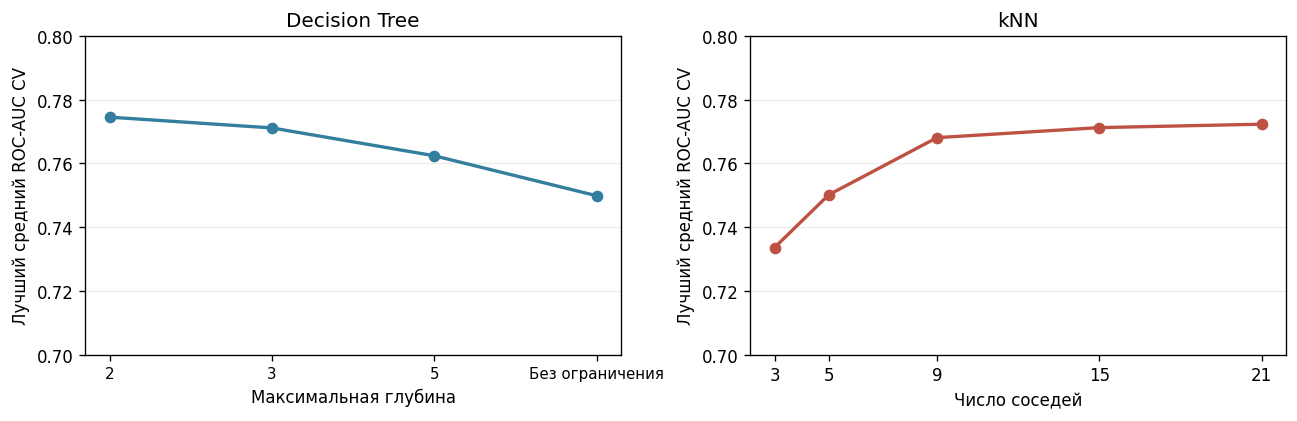

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(10.7, 3.4), layout="constrained")
tree_grid = saved_grids["Decision Tree"].copy()
tree_grid["Глубина"] = tree_grid["param_model__max_depth"].map(
    lambda depth: str(int(depth)) if pd.notna(depth) else "Без ограничения"
)
tree_auc = tree_grid.groupby("Глубина", sort=False)["mean_test_score"].max()
axes[0].plot(tree_auc.index, tree_auc, marker="o", color="#337e9e", lw=2)
axes[0].set(xlabel="Максимальная глубина", ylabel="Лучший средний ROC-AUC CV",
            title="Decision Tree", ylim=(0.70, 0.80))
axes[0].tick_params(axis="x", labelsize=9)

knn_auc = saved_grids["kNN"].groupby("param_model__n_neighbors")["mean_test_score"].max()
axes[1].plot(knn_auc.index, knn_auc, marker="o", color="#be5143", lw=2)
axes[1].set(xlabel="Число соседей", ylabel="Лучший средний ROC-AUC CV",
            title="kNN", ylim=(0.70, 0.80), xticks=knn_auc.index)
for ax in axes:
    ax.grid(axis="y", alpha=0.23)
plt.show()

- **Наивный Байес.** У GaussianNB увеличение `var_smoothing` до 1 подняло ROC-AUC с 0,7601 до 0,7664. У MultinomialNB пять интервалов дали 0,7609 против 0,7492 при трёх интервалах (сравнение лучших конфигураций). У ComplementNB добавление нормировки подняло лучший результат с 0,7609 до 0,7616. У BernoulliNB лучший порог после стандартизации равен 0, а базовая конфигурация уже достигала 0,7322.
- **Дерево решений.** Ограничение глубины до 2 дало самый большой прирост относительно базовой модели, с 0,6445 до 0,7745. Даже лучший вариант без ограничения глубины достиг только 0,7499.
- **LDA.** Переход от SVD к `lsqr` с автоматической регуляризацией повысил ROC-AUC с 0,7911 до 0,7922. Это лучший средний результат среди классических моделей.
- **SVM.** Линейное ядро с `C=0.1` дало 0,7897. Лучший вариант с RBF-ядром дал 0,7846.
- **kNN.** Лучший ROC-AUC рос с 0,7336 при 3 соседях до 0,7723 при 21. В лучшей конфигурации использовались манхэттенское расстояние и равные веса.

## 6. Нейросеть TensorFlow

Модель построена на Keras Sequential. Вход содержит четыре стандартизованных признака. Базовая конфигурация N0 использует один полносвязный слой из 16 нейронов с ReLU, а выходной слой из одного нейрона с sigmoid выдаёт вероятность класса 1. Функция потерь — бинарная кросс-энтропия, оптимизатор — Adam. Для перехода от вероятности к классу применяется порог 0,5.

В каждом из семи дополнительных опытов изменялся один параметр базовой конфигурации. В опыте N5 изменялась архитектура целиком: добавлен второй скрытый слой и заданы размеры 32 и 16. Сравнение проведено после последней эпохи по ROC-AUC, рассчитанному функцией `roc_auc_score` по прогнозам на валидации.

,Нейроны в слоях,Активация,Эпохи,Батч,Learning rate,Val ROC-AUC,Val Accuracy,Val Loss,Train Accuracy
id,,,,,,,,,
N0,16,relu,60,16,0.001,0.6667,0.6441,0.6701,0.7296
N1,16,relu,30,16,0.001,0.6644,0.6441,0.6676,0.7167
N2,16,relu,120,16,0.001,0.6713,0.6441,0.6647,0.7339
N3,16,relu,60,32,0.001,0.6632,0.6441,0.6652,0.7167
N4,8,relu,60,16,0.001,0.6644,0.6271,0.6880,0.7382
N5,32-16,relu,60,16,0.001,0.6885,0.6102,0.6625,0.7468
N6,16,tanh,60,16,0.001,0.6793,0.6441,0.6560,0.7339
N7,16,relu,60,16,0.010,0.6874,0.6610,0.6580,0.7554


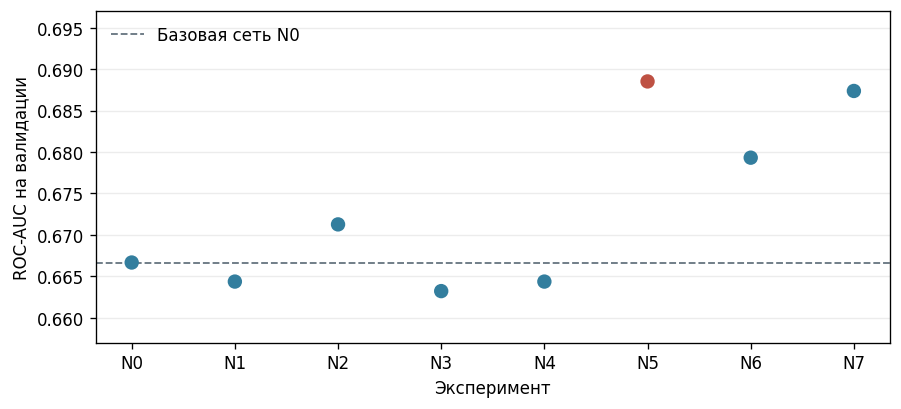

In [9]:
nn_table = saved_nn.rename(columns={
    "units": "Нейроны в слоях", "activation": "Активация", "epochs": "Эпохи",
    "batch_size": "Батч", "lr": "Learning rate", "Val_AUC": "Val ROC-AUC",
    "Val_Accuracy": "Val Accuracy", "Val_loss": "Val Loss",
    "Train_Accuracy": "Train Accuracy",
})
display(nn_table.round(4))

fig, ax = plt.subplots(figsize=(7.4, 3.3), layout="constrained")
colors = ["#be5143" if run == "N5" else "#337e9e" for run in saved_nn.index]
ax.scatter(saved_nn.index, saved_nn["Val_AUC"], c=colors, s=58, zorder=3)
ax.axhline(saved_nn.loc["N0", "Val_AUC"], color="#687681", ls="--", lw=1.1, label="Базовая сеть N0")
ax.set(ylim=(0.657, 0.697), xlabel="Эксперимент", ylabel="ROC-AUC на валидации")
ax.legend(loc="upper left", frameon=False)
ax.grid(axis="y", alpha=0.24)
plt.show()

По выбранной метрике лучшей стала N5 с ROC-AUC **0,6885** против **0,6667** у N0. Увеличение числа эпох до 120 (N2) дало 0,6713, уменьшение до 30 (N1) — 0,6644. Батч 32 (N3) дал 0,6632, слой из 8 нейронов (N4) — 0,6644, активация tanh (N6) — 0,6793. Повышение learning rate до 0,01 (N7) дало ROC-AUC **0,6874** и максимальную валидационную Accuracy **0,6610**. Разница ROC-AUC между N5 и N7 около 0,0011 на 59 валидационных примерах.

### 6.1. Графики обучения и TensorBoard

Ниже показаны кривые N0 и N5 из истории фактического запуска в JupyterLab. В TensorBoard для каждого опыта отображались серии `train` и `validation` с тегами `epoch_loss`, `epoch_accuracy` и `epoch_auc`. TensorBoard показывает приближённый ROC-AUC Keras по сетке порогов. Например, последнее значение `epoch_auc` для N5 на валидации — 0,6891, а расчёт Scikit-Learn по прогнозам дал 0,6885.

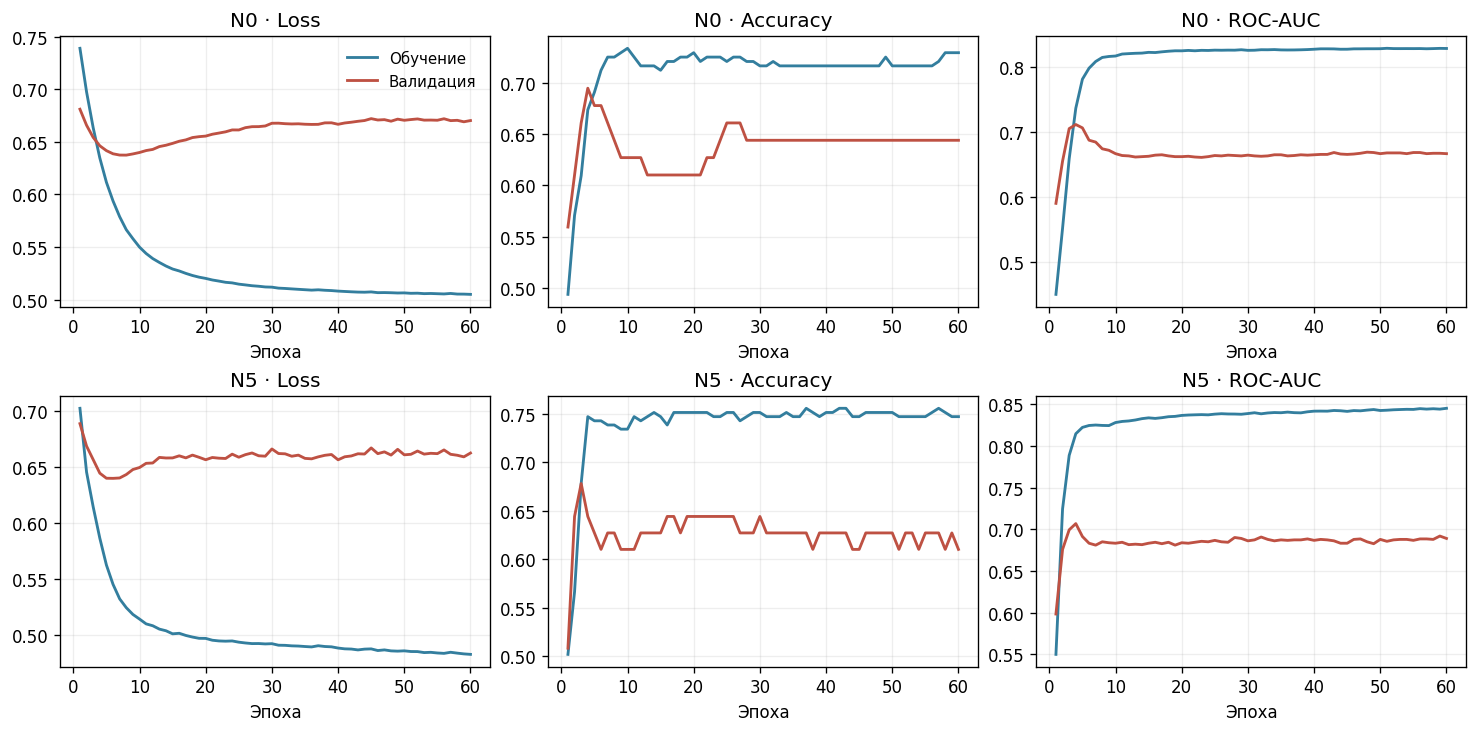

In [10]:
fig, axes = plt.subplots(2, 3, figsize=(12.2, 6.0), layout="constrained")
for row, run in enumerate(("N0", "N5")):
    history = saved_histories[run]
    epochs = range(1, len(history["loss"]) + 1)
    for ax, metric, title in zip(axes[row], ("loss", "accuracy", "auc"), ("Loss", "Accuracy", "ROC-AUC")):
        ax.plot(epochs, history[metric], color="#337e9e", lw=1.7, label="Обучение")
        ax.plot(epochs, history["val_" + metric], color="#be5143", lw=1.7, label="Валидация")
        ax.set(title=f"{run} · {title}", xlabel="Эпоха")
        ax.grid(alpha=0.21)
axes[0, 0].legend(loc="best", frameon=False, fontsize=9)
plt.show()

У N5 к 60-й эпохе ошибка обучения снизилась до 0,4831, а валидационная ошибка составила 0,6625 после минимума 0,6399. Рост разрыва указывает на признаки переобучения. В этом эксперименте конфигурации сравнивались после заданного числа эпох, поэтому ранняя остановка не применялась.

### 6.2. Повторное обучение и просмотр журналов

Чтобы повторить опыты, установите `RETRAIN_TF = True` в первой ячейке с кодом и выполните блокнот целиком. После выбора по валидационному ROC-AUC сеть обучается заново на 292 тренировочных днях. Итоги повторного прогона выводятся отдельно. Они могут отличаться при смене версии TensorFlow или вычислительной среды. В исходном запуске использовался TensorFlow 2.16.2.

Для просмотра имеющихся журналов установите `OPEN_TENSORBOARD = True`. TensorBoard читает папку `logs/lab2` относительно рабочей папки JupyterLab. В **Time Series** можно выбрать пары `N0/train` и `N0/validation` или `N5/train` и `N5/validation`. Исходные файлы событий хранятся в локальной папке запуска. При повторном обучении создаётся отдельная подпапка с новыми журналами.

In [11]:
def build_network(tf, config):
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(SEED)
    hidden_units = [int(units) for units in str(config["units"]).split("-")]
    model = tf.keras.Sequential([
        tf.keras.Input(shape=(len(FEATURES),)),
        *[tf.keras.layers.Dense(units, activation=config["activation"]) for units in hidden_units],
        tf.keras.layers.Dense(1, activation="sigmoid"),
    ])
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=float(config["lr"])),
        loss="binary_crossentropy",
        metrics=["accuracy", tf.keras.metrics.AUC(name="auc")],
    )
    return model


def run_tensorflow_experiments():
    import tensorflow as tf

    X_inner, X_val, y_inner, y_val = train_test_split(
        X_train, y_train, test_size=0.20, stratify=y_train, random_state=SEED,
    )
    scaler = StandardScaler().fit(X_inner)
    train_input = scaler.transform(X_inner).astype("float32")
    val_input = scaler.transform(X_val).astype("float32")
    run_dir = LOG_DIR / datetime.now().strftime("rerun-%Y%m%d-%H%M%S")
    experiments = []

    for run, config in saved_nn.iterrows():
        model = build_network(tf, config)
        history = model.fit(
            train_input, y_inner.to_numpy(),
            validation_data=(val_input, y_val.to_numpy()),
            epochs=int(config["epochs"]), batch_size=int(config["batch_size"]), verbose=0,
            callbacks=[tf.keras.callbacks.TensorBoard(log_dir=str(run_dir / run))],
        )
        probabilities = model.predict(val_input, verbose=0).ravel()
        experiments.append({
            "Опыт": run,
            "Val ROC-AUC": roc_auc_score(y_val, probabilities),
            "Val Accuracy": accuracy_score(y_val, probabilities > 0.5),
            "Val Loss": history.history["val_loss"][-1],
        })

    experiments = pd.DataFrame(experiments).set_index("Опыт")
    best_run = experiments["Val ROC-AUC"].idxmax()
    best = saved_nn.loc[best_run]
    final_scaler = StandardScaler().fit(X_train)
    final_model = build_network(tf, best)
    final_model.fit(
        final_scaler.transform(X_train).astype("float32"), y_train.to_numpy(),
        epochs=int(best["epochs"]), batch_size=int(best["batch_size"]), verbose=0,
        callbacks=[tf.keras.callbacks.TensorBoard(log_dir=str(run_dir / "refit"))],
    )
    probabilities = final_model.predict(
        final_scaler.transform(X_test).astype("float32"), verbose=0,
    ).ravel()
    return experiments, best_run, probabilities, run_dir


if RETRAIN_TF:
    tf_results, tf_best_run, tf_scores, tf_log_dir = run_tensorflow_experiments()
    display(tf_results.round(4))
    print(f"Выбран опыт {tf_best_run}. Журналы: {tf_log_dir.resolve()}")
else:
    print("Для отчёта использован сохранённый запуск TensorFlow.")

Для отчёта использован сохранённый запуск TensorFlow.


In [12]:
if OPEN_TENSORBOARD:
    if any(LOG_DIR.rglob("events.out.tfevents.*")):
        get_ipython().run_line_magic("load_ext", "tensorboard")
        get_ipython().run_line_magic("tensorboard", f"--logdir {LOG_DIR.as_posix()}")
    else:
        print(f"Файлы событий не найдены в {LOG_DIR.resolve()}.")
        print("Откройте блокнот из папки исходного запуска или включите повторное обучение.")

## 7. Сравнение на тестовой выборке

- **Accuracy** — доля правильных ответов среди всех 73 тестовых дней.
- **Precision** — доля истинно положительных ответов среди всех предсказаний класса 1.
- **Recall** — доля найденных дней класса 1 среди всех фактических дней этого класса.
- **F1** — гармоническое среднее Precision и Recall.
- **ROC-AUC** — площадь под ROC-кривой, рассчитанная по непрерывным оценкам моделей. Для LDA и SVM использована оценка `decision_function`, для остальных — вероятность класса 1. У DummyClassifier нет положительных предсказаний, поэтому его Precision, Recall и F1 равны 0 при `zero_division=0`.

Таблица пересчитана из сохранённых прогнозов для одних и тех же тестовых дней. Следом показаны ROC-кривые и матрицы ошибок.

In [13]:
def evaluate(y_true, predicted, scores):
    return {
        "Accuracy": accuracy_score(y_true, predicted),
        "Precision": precision_score(y_true, predicted, zero_division=0),
        "Recall": recall_score(y_true, predicted, zero_division=0),
        "F1": f1_score(y_true, predicted, zero_division=0),
        "ROC_AUC": roc_auc_score(y_true, scores),
    }


def metrics_table(predictions, names):
    return pd.DataFrame.from_dict({
        name: evaluate(y_test, predictions[name + "_pred"], predictions[name + "_score"])
        for name in names
    }, orient="index")[METRICS]


assert np.array_equal(saved_predictions["y_true"], y_test)
test_metrics = metrics_table(saved_predictions, saved_metrics.index)
np.testing.assert_allclose(test_metrics, saved_metrics[METRICS], atol=1e-12, rtol=0)
display(test_metrics.rename(columns={"ROC_AUC": "ROC-AUC"}).round(4))

replay_metrics = metrics_table(classical_scores, saved_metrics.index[:-1])
if np.allclose(replay_metrics, test_metrics.loc[replay_metrics.index], rtol=0, atol=1e-10):
    print("Метрики повторного расчёта Scikit-Learn совпали с сохранёнными.")
else:
    print(f"Метрики повторного расчёта Scikit-Learn {sklearn.__version__}")
    display(replay_metrics.round(4))

if RETRAIN_TF:
    print("Метрики повторного обучения TensorFlow")
    display(pd.DataFrame([evaluate(y_test, tf_scores > 0.5, tf_scores)]).round(4))

,Accuracy,Precision,Recall,F1,ROC-AUC
Dummy (baseline),0.5205,0.0000,0.0000,0.0000,0.5000
GaussianNB,0.7671,0.7250,0.8286,0.7733,0.8835
MultinomialNB,0.7260,0.6923,0.7714,0.7297,0.8733
ComplementNB,0.7397,0.6818,0.8571,0.7595,0.8680
BernoulliNB,0.7397,0.7500,0.6857,0.7164,0.8109
Decision Tree,0.7808,0.7111,0.9143,0.8000,0.8662
LDA,0.7945,0.7778,0.8000,0.7887,0.9083
SVM,0.8082,0.7838,0.8286,0.8056,0.9083
kNN,0.7945,0.8125,0.7429,0.7761,0.8741
TensorFlow NN,0.8219,0.8235,0.8000,0.8116,0.9030


Метрики повторного расчёта Scikit-Learn совпали с сохранёнными.


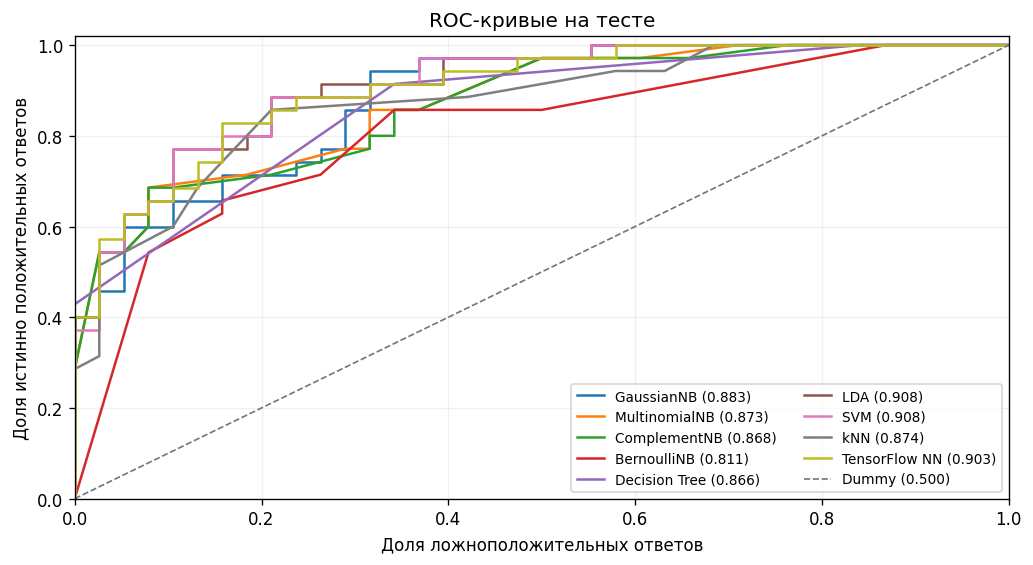

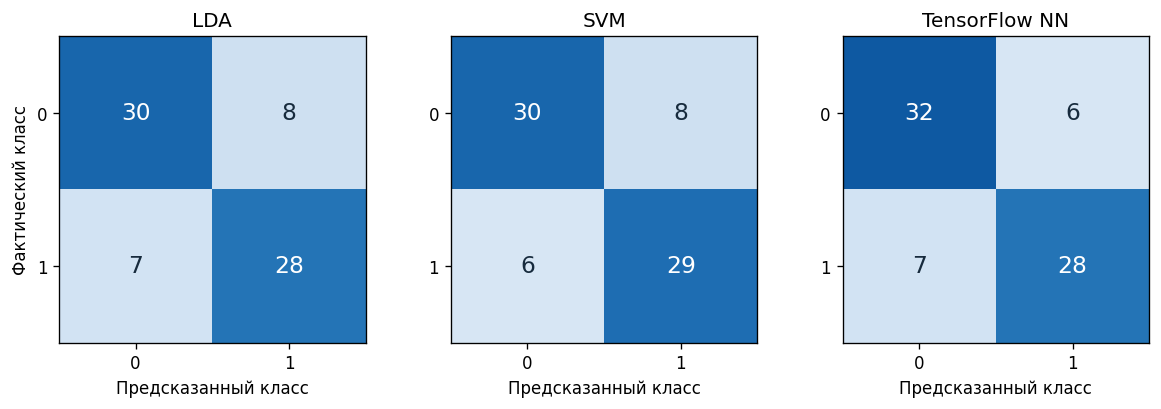

In [14]:
fig, ax = plt.subplots(figsize=(8.5, 4.6), layout="constrained")
for name in test_metrics.index:
    if name == "Dummy (baseline)":
        continue
    fpr, tpr, _ = roc_curve(y_test, saved_predictions[name + "_score"])
    ax.plot(fpr, tpr, label=f"{name} ({test_metrics.loc[name, 'ROC_AUC']:.3f})")
ax.plot([0, 1], [0, 1], color="#697782", ls="--", lw=1, label="Dummy (0.500)")
ax.set(xlim=(0, 1), ylim=(0, 1.02), xlabel="Доля ложноположительных ответов",
       ylabel="Доля истинно положительных ответов", title="ROC-кривые на тесте")
ax.legend(loc="lower right", fontsize=8.2, ncols=2)
ax.grid(alpha=0.18)
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(10, 3.3), layout="constrained")
for ax, name in zip(axes, ("LDA", "SVM", "TensorFlow NN")):
    matrix = confusion_matrix(y_test, saved_predictions[name + "_pred"], labels=[0, 1])
    ax.imshow(matrix, cmap="Blues", vmin=0, vmax=38)
    for (row, col), count in np.ndenumerate(matrix):
        ax.text(col, row, str(count), ha="center", va="center",
                color="white" if count > 20 else "#172b3d", fontsize=14)
    ax.set(title=name, xlabel="Предсказанный класс", xticks=[0, 1], yticks=[0, 1])
axes[0].set_ylabel("Фактический класс")
plt.show()

**LDA и SVM** получили одинаковый тестовый ROC-AUC до четырёх знаков (**0,9083**). LDA имел чуть больший средний ROC-AUC в кросс-валидации классических моделей (0,7922 против 0,7897) и выбран по этому критерию. У SVM выше тестовая Accuracy (0,8082 против 0,7945).

**Нейросеть N5** после переобучения на всей обучающей части достигла наибольших Accuracy (**0,8219**), Precision (**0,8235**) и F1 (**0,8116**). Она верно классифицировала 60 из 73 дней, SVM — 59, LDA — 58. У N5 ROC-AUC **0,9030**, на 0,0053 ниже LDA и SVM. Дерево решений достигло наибольшего Recall (**0,9143**): оно нашло 32 из 35 дней класса 1, но выдало 13 ложных срабатываний.

## 8. Заключение

На четырёх погодных признаках все обученные модели превзошли контрольный классификатор по ROC-AUC. Для ранжирования дней по вероятности высокого потребления в рамках этого эксперимента выбрана LDA: она дала наибольший средний ROC-AUC среди классических моделей и разделила первое место на тесте с SVM. С порогом классификации 0,5 нейросеть N5 дала лучший баланс Precision и Recall по F1. На тесте из 73 дней разница в Accuracy между N5 и SVM составила один правильный ответ.